In [22]:
import numpy as np
import h5py
import time
from tqdm import tqdm
import matplotlib.pyplot as plt

def generate_sample(a: float, b: float, c: float, d: float):  
    scale = 10
    x = scale * np.random.rand() - scale / 2
    y = a * x**3 + b * x**2 + c * x + d
    
    sample = {
        "input" : x,
        "label" : y + 0.05 * np.abs(y) * np.random.randn(),
    }
    
    return sample

# generate sample ------------------------------------------------------------------------------------------------------
N          = 10000
collection = []
for i in tqdm(range(N), ncols=120, desc="generating"):
    sample = generate_sample(a=0.1, b=0.05, c=-2.0, d=-0.7)
    collection.append(sample)

# save data ------------------------------------------------------------------------------------------------------------
with h5py.File(f"./collections/{time.strftime('%Y-%m-%d--%H-%M-%S')}--X{N:05}.h5", "w") as f:
    # Iterate over your list
    for i, item in tqdm(enumerate(collection), total=len(collection), ncols=120, desc="saving    "):
        group = f.create_group(f"item_{i}")
        for key, array in item.items():
            group.create_dataset(key, data=array)

saving    : 100%|███████████████████████████████████████████████████████████████| 10000/10000 [00:05<00:00, 1684.90it/s]


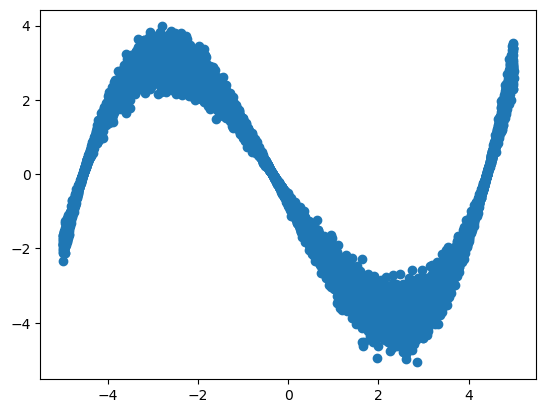

In [21]:
X = []
Y = []
for sample in collection:
    X.append(sample["input"])
    Y.append(sample["label"])
    
X = np.array(X)
Y = np.array(Y)

plt.plot(X, Y, "o")